In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights, 
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData)

from modules.utilities import load_dataset, transform_dataset, transform_datasets
from modules.process import train_and_validate_model

In [2]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
DATA_PATH_VALIDATION: Path = PROJECT_ROOT / 'mp_data_validation'
DATA_PATH_TEST: Path = PROJECT_ROOT / 'mp_data_new_test'

# TODO: record test data
TEST_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [3]:
# load data
raw_data, labels, actions = load_dataset(DATA_PATH, 
                                             feature_extracter=feature_extracter)

raw_validation, validation_labels, actions_validation = load_dataset(DATA_PATH_VALIDATION,
                                                feature_extracter=feature_extracter)

normalized_data, normalized_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_normalized)
weighted_data, weighted_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_weighted)
centered_data, centered_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_centered)
all_transformations_data, all_transformations_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_all)

In [4]:
baseline_model, baseline_training = train_and_validate_model(model_factory=model_factory,
                         actions=actions,
                         train_dataset=raw_data,
                         train_labels=raw_labels,
                         validation_dataset=raw_validation,
                         validation_labels=validation_labels,
                         nr_of_epochs=NR_OF_EPOCHS)

normalized_model, normalized_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=normalized_data,
                            train_labels=raw_labels,
                            validation_dataset=normalized_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

weighted_model, weighted_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=weighted_data,
                            train_labels=labels,
                            validation_dataset=weighted_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

centered_model, centered_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=centered_data,
                            train_labels=labels,
                            validation_dataset=centered_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

all_transformations_model, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=all_transformations_data,
                            train_labels=labels,
                            validation_dataset=all_transformations_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)


NameError: name 'raw_labels' is not defined

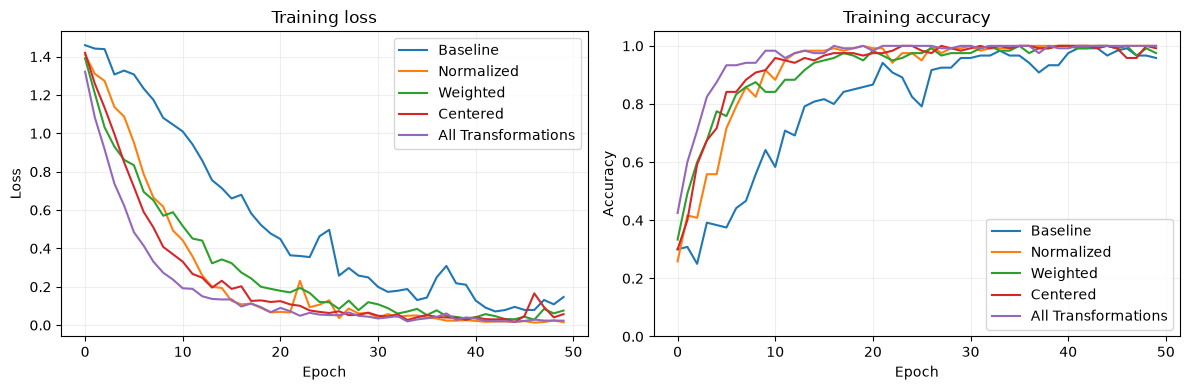

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, history in [("Baseline", baseline_training),
                       ("Normalized", normalized_training),
                       ("Weighted", weighted_training),
                       ("Centered", centered_training),
                       ("All Transformations", all_transformations_training)]:
    axes[0].plot(history.history["loss"], label=label)
    axes[1].plot(history.history["categorical_accuracy"], label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)

# load data
raw_test, test_labels, actions = load_dataset(DATA_PATH_TEST, 
                                              feature_extracter=feature_extracter,
                                              fearure_transformer=feature_transformer_all)

test_transformed = transform_dataset(raw_test, feature_transformer=feature_transformer_all)

original_base_pred = predictions(baseline_model, raw_test)
original_norm_pred = predictions(normalized_model, test_transformed)
original_results = {
    "Baseline": accuracy_score(test_labels, original_base_pred),
    "Normalized": accuracy_score(test_labels, original_norm_pred),
}
print("Original test set (n=%d):" % len(test_labels), original_results)
print("Difference in percentage points:", round(100 * (original_results["Normalized"] - original_results["Baseline"]), 2))

Original test set (n=120): {'Baseline': 0.5416666666666666, 'Normalized': 0.45}
Difference in percentage points: -9.17
